In [1]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#bk_file = "../data/dipole/bk_samplefrommvefit.dat"
bk_file = '../data/nucleus/0/ic_197_0.dat'
BKinterpolator = dipole.BKDipole(bk_file)
#init = [1.0, 0.8, 1.0, 1.0]
init = [1.0, 1.0, 1.0, 1.0]
lbounds = [0.001, 0.1, 1/np.exp(1), 0.001]
ubounds = [10.0, 100.0, 100.0, 10.0]
grid_size = 5 #100
y_max = 8.0
y_array = np.linspace(0, y_max, grid_size)
r = np.logspace(-3, 2, 200)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function

fit_params_array = np.ones((len(y_array), 4))
i = 0
file_params = open("test.dat", "w")
for y in y_array:
    minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds, lsmethod ='trf')
    out = minimizer.fit_ls()
    fit_params = out.x
    fit_params_array[i, :] = fit_params
    #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    print('### y = ', np.round(y,3))
    print(fit_params)
    #init = fit_params
    i += 1

with file_params:
    file_params.write("# Parameter file of fit of dipole from {}".format(bk_file) + "\n")
    file_params.write("# y ranges from 0 to {} in {} steps".format(y_max, grid_size) + "\n")
    file_params.write("# Columns: y, Qs2, gamma, ec, p" + "\n")
    for j in range(len(y_array)):
        file_params.write("{: .6e} {: .6e} {: .6e} {: .6e} {: .6e}\n".format(y_array[j], fit_params_array[j,0], fit_params_array[j,1], fit_params_array[j,2], fit_params_array[j,3]))

/home/caaucasu/sidis_fit/src/dipole.py:109: RuntimeWarning: divide by zero encountered in log
  N_values = [np.log(self.N(Y, r)) for r in r_values]


ValueError: Residuals are not finite in the initial point.

Text(0, 0.5, 'N(r,y)')

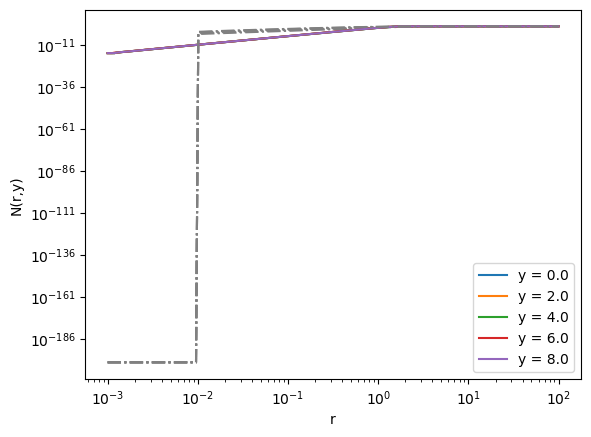

In [ ]:
i = 0
for y in y_array:
    fit_params = fit_params_array[i, :]
    fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    plt.plot(r, np.exp(fit_func), '-', label='y = '+str(np.round(y,3)))
    plt.plot(r, np.exp(Nyr(y,r)), '-.', color = 'gray')
    i += 1
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('r')
plt.ylabel('N(r,y)')
# plt.ylim(1e-1, 1e1)


## Get Fourier transform

In [41]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(y,k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def log_S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

[1.00000000e-02 1.20679264e-02 1.45634848e-02 1.75751062e-02
 2.12095089e-02 2.55954792e-02 3.08884360e-02 3.72759372e-02
 4.49843267e-02 5.42867544e-02 6.55128557e-02 7.90604321e-02
 9.54095476e-02 1.15139540e-01 1.38949549e-01 1.67683294e-01
 2.02358965e-01 2.44205309e-01 2.94705170e-01 3.55648031e-01
 4.29193426e-01 5.17947468e-01 6.25055193e-01 7.54312006e-01
 9.10298178e-01 1.09854114e+00 1.32571137e+00 1.59985872e+00
 1.93069773e+00 2.32995181e+00 2.81176870e+00 3.39322177e+00
 4.09491506e+00 4.94171336e+00 5.96362332e+00 7.19685673e+00
 8.68511374e+00 1.04811313e+01 1.26485522e+01 1.52641797e+01
 1.84206997e+01 2.22299648e+01 2.68269580e+01 3.23745754e+01
 3.90693994e+01 4.71486636e+01 5.68986603e+01 6.86648845e+01
 8.28642773e+01 1.00000000e+02]


/tmp/ipykernel_1267121/1506258829.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


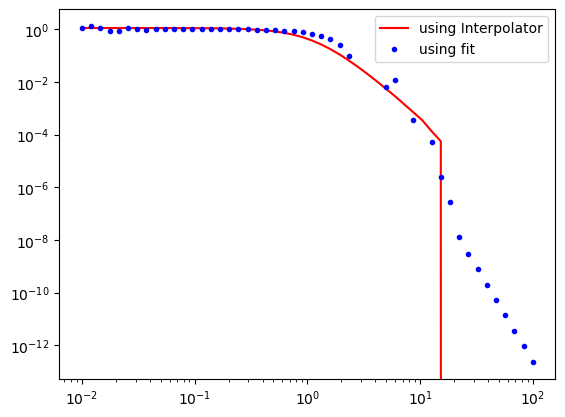

In [ ]:
fit_params = fit_params_array[grid_size-1] # last rapidity
k = np.logspace(-2, 2, 50)
print(k)
Sk = S(y_max,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')

[1.00000000e-02 1.20679264e-02 1.45634848e-02 1.75751062e-02
 2.12095089e-02 2.55954792e-02 3.08884360e-02 3.72759372e-02
 4.49843267e-02 5.42867544e-02 6.55128557e-02 7.90604321e-02
 9.54095476e-02 1.15139540e-01 1.38949549e-01 1.67683294e-01
 2.02358965e-01 2.44205309e-01 2.94705170e-01 3.55648031e-01
 4.29193426e-01 5.17947468e-01 6.25055193e-01 7.54312006e-01
 9.10298178e-01 1.09854114e+00 1.32571137e+00 1.59985872e+00
 1.93069773e+00 2.32995181e+00 2.81176870e+00 3.39322177e+00
 4.09491506e+00 4.94171336e+00 5.96362332e+00 7.19685673e+00
 8.68511374e+00 1.04811313e+01 1.26485522e+01 1.52641797e+01
 1.84206997e+01 2.22299648e+01 2.68269580e+01 3.23745754e+01
 3.90693994e+01 4.71486636e+01 5.68986603e+01 6.86648845e+01
 8.28642773e+01 1.00000000e+02]


/tmp/ipykernel_1267121/1506258829.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


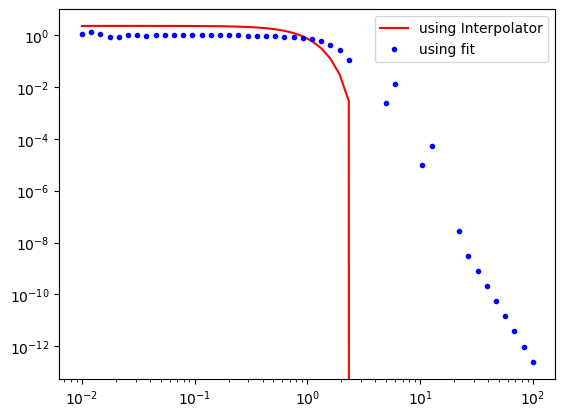

In [43]:
fit_params = fit_params_array[0]
k = np.logspace(-2, 2, 50)
print(k)
Sk = S(0.0,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using fit', color='blue')
plt.legend()
plt.xscale('log')
plt.yscale('log')

/tmp/ipykernel_1267121/1506258829.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


Text(0, 0.5, 'log S(k)')

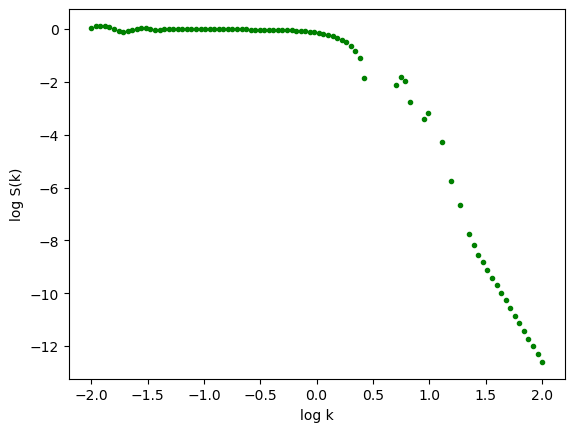

In [44]:
import pandas as pd
k_grid_size = 100#500
log_k_grid = np.linspace(-2, 2, k_grid_size)
log_Sk2 = log_S2(10**log_k_grid, fit_params)
plt.plot(log_k_grid, log_Sk2, '.',label='using fit at y=0.0', color='green')
plt.xlabel('log k')
plt.ylabel('log S(k)')

In [45]:
y_array_repeat = np.repeat(y_array, k_grid_size)
log_k_min = -2
log_k_max = 2
log_k_all = []
log_Sk2_all = []



for i in range(len(y_array)):
    fit_params = fit_params_array[i, :]
    log_k_grid = np.linspace(log_k_min, log_k_max, k_grid_size)
    log_Sk2 = log_S2(10**log_k_grid, fit_params)
    log_k_all.extend(log_k_grid)
    log_Sk2_all.extend(log_Sk2)

data = {'y': y_array_repeat, 'log10_k':log_k_all, 'log10_S(k)':log_Sk2_all}
df = pd.DataFrame(data)
print(np.shape(y_array_repeat))
print(np.shape(log_k_all))
print(np.shape(log_Sk2_all))

/tmp/ipykernel_1267121/1506258829.py:24: RuntimeWarning: invalid value encountered in log10
  sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]


(5000,)
(5000,)
(5000,)


In [46]:
# csv_file = '../data/BKfit_Sk_data.csv'
# comments = ['## Generated from BK dipole with initial condition: MVe model, Q_s0^2 = 0.0544245 GeV^2, \gamma = 1, coefficient of E inside Log is 58.5321',
#                    '## Fitted to file {0}'.format(bk_file),
#                    '## Note definition of log S(k): log_S(k) = log10 S(k) = log10 [ \int r dr J0(k r) (1 - N(r)) ]',
#                    '## log10 k grid ranges from {0} to {1} with {2} points'.format(log_k_min, log_k_max, k_grid_size),
#                    '## y grid ranges from 0 to {0} with {1} points'.format(y_max, grid_size),]

# if save_files:
#     with open(csv_file, 'w') as f:
#         for comment in comments:
#             f.write(comment + '\n')
# df.to_csv(csv_file, index=False, sep = ' ', columns=['y', 'log10_k', 'log10_S(k)'], mode='a', float_format='%.6e') if save_files else None